In [ ]:
# Install ultralytics (YOLOv8)
!pip install ultralytics -q

# Mount Google Drive to save/load data & checkpoints
from google.colab import drive
drive.mount('/content/drive')

# Verify GPU
import torch
print(f"GPU available: {torch.cuda.is_available()}")
print(f"GPU name: {torch.cuda.get_device_name(0)}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 26.1 MB/s eta 0:00:00
Mounted at /content/drive
GPU available: True
GPU name: Tesla T4


In [ ]:
from google.colab import drive
import zipfile, os, yaml, glob, shutil

drive.mount('/content/drive')

# Find your zip automatically — no need to type the exact path
search_root = '/content/drive/MyDrive'
zip_path = None

for root, dirs, files in os.walk(search_root):
    for f in files:
        if f.endswith('.zip') and ('Panoramic' in f or 'Dental' in f or 'FDI' in f):
            zip_path = os.path.join(root, f)
            print(f"Found: {zip_path}")
            break

# If auto-find didn't work, set manually:
# zip_path = '/content/drive/MyDrive/YOUR_FILE_NAME.zip'

print(f"\nZip size: {os.path.getsize(zip_path)/1e6:.1f} MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found: /content/drive/MyDrive/Panoramic-Dental-Xray-FDI.v1-stretch---rotate.yolov8 (1).zip

Zip size: 661.5 MB


In [ ]:
EXTRACT_TO = '/content/dental_dataset'

if os.path.exists(EXTRACT_TO):
    shutil.rmtree(EXTRACT_TO)

os.makedirs(EXTRACT_TO, exist_ok=True)

print("Extracting zip...")
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(EXTRACT_TO)
print("Extraction complete.\n")

# Show extracted structure
for root, dirs, files in os.walk(EXTRACT_TO):
    depth = root.replace(EXTRACT_TO, '').count(os.sep)
    if depth > 2:
        continue
    indent = '  ' * depth
    folder_name = os.path.basename(root)
    file_count = len(files)
    print(f"{indent}{folder_name}/  ({file_count} files)")

Extracting zip...
Extraction complete.

dental_dataset/  (3 files)
  train/  (0 files)
    images/  (3032 files)
    labels/  (3032 files)
  test/  (0 files)
    images/  (156 files)
    labels/  (156 files)
  valid/  (0 files)
    images/  (315 files)
    labels/  (315 files)


In [ ]:
# Roboflow zips sometimes have a nested folder inside
# This finds the actual dataset root automatically
def find_dataset_root(base):
    yaml_files = glob.glob(f"{base}/**/data.yaml", recursive=True)
    if not yaml_files:
        raise FileNotFoundError("No data.yaml found! Check zip contents.")
    return os.path.dirname(yaml_files[0])

DATASET_ROOT = find_dataset_root(EXTRACT_TO)
print(f"Dataset root: {DATASET_ROOT}")

YAML_PATH = f"{DATASET_ROOT}/data.yaml"

# Read original yaml
with open(YAML_PATH, 'r') as f:
    cfg = yaml.safe_load(f)

print(f"\nOriginal yaml:")
for k, v in cfg.items():
    print(f"  {k}: {v}")

# Fix paths for Colab
cfg['path']  = DATASET_ROOT
cfg['train'] = 'train/images'
cfg['val']   = 'valid/images'    # Roboflow always uses 'valid' not 'val'
cfg['test']  = 'test/images'

with open(YAML_PATH, 'w') as f:
    yaml.dump(cfg, f, default_flow_style=False)

print(f"\nFixed yaml — paths now point to: {DATASET_ROOT}")
print(f"Classes ({cfg['nc']}): {cfg['names']}")

Dataset root: /content/dental_dataset

Original yaml:
  train: ../train/images
  val: ../valid/images
  test: ../test/images
  nc: 32
  names: ['11', '12', '13', '14', '15', '16', '17', '18', '21', '22', '23', '24', '25', '26', '27', '28', '31', '32', '33', '34', '35', '36', '37', '38', '41', '42', '43', '44', '45', '46', '47', '48']
  roboflow: {'workspace': 'dentalxray', 'project': 'panoramic-dental-xray-fdi', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/dentalxray/panoramic-dental-xray-fdi/dataset/1'}

Fixed yaml — paths now point to: /content/dental_dataset
Classes (32): ['11', '12', '13', '14', '15', '16', '17', '18', '21', '22', '23', '24', '25', '26', '27', '28', '31', '32', '33', '34', '35', '36', '37', '38', '41', '42', '43', '44', '45', '46', '47', '48']


In [ ]:
all_ok = True

for split in ['train', 'valid', 'test']:
    img_dir = f"{DATASET_ROOT}/{split}/images"
    lbl_dir = f"{DATASET_ROOT}/{split}/labels"

    imgs = glob.glob(f"{img_dir}/*") if os.path.exists(img_dir) else []
    lbls = glob.glob(f"{lbl_dir}/*") if os.path.exists(lbl_dir) else []

    status = "OK" if len(imgs) > 0 and len(imgs) == len(lbls) else "MISMATCH"
    if status == "MISMATCH":
        all_ok = False
    print(f"  {split:6s} → {len(imgs):4d} images  {len(lbls):4d} labels  [{status}]")

# Peek at one label file to confirm format
sample_labels = glob.glob(f"{DATASET_ROOT}/train/labels/*.txt")
if sample_labels:
    print(f"\nSample label file ({os.path.basename(sample_labels[0])}):")
    with open(sample_labels[0]) as f:
        for line in f.readlines()[:10]:
            parts = line.strip().split()
            cls_id = int(parts[0])
            fdi = cfg['names'][cls_id]
            print(f"  class {cls_id} = tooth {fdi}  |  raw: {line.strip()}")

print(f"\nDataset ready: {all_ok}")

  train  → 3032 images  3032 labels  [OK]
  valid  →  315 images   315 labels  [OK]
  test   →  156 images   156 labels  [OK]

Sample label file (396_jpg.rf.8bc3e2f14e0125746a04334e0b7abd54.txt):
  class 6 = tooth 17  |  raw: 6 0.22635962734374998 0.3876953125 0.21999020078124998 0.369140625 0.20921117109375 0.400390625 0.20627143593750003 0.4267578125 0.20284174453124998 0.466796875 0.19549240546875 0.490234375 0.19549240546875 0.5263671875 0.21460068593749998 0.5205078125 0.225379715625 0.5380859375 0.23811856953125 0.53125 0.23811856953125 0.4921875 0.23517883359375 0.466796875 0.23517883359375 0.4501953125 0.23076923046875 0.423828125 0.22635962734374998 0.3876953125
  class 5 = tooth 16  |  raw: 5 0.23370896640625 0.5283203125 0.23713865781250001 0.5673828125 0.2454679078125 0.576171875 0.260656540625 0.578125 0.278784909375 0.580078125 0.295933365625 0.5478515625 0.287604115625 0.513671875 0.2851543359375 0.484375 0.27976482109375 0.4453125 0.27437530625 0.419921875 0.26702596796

In [ ]:
!pip install ultralytics -q

import torch
from ultralytics import YOLO

print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

model = YOLO('yolov8n.pt')

model.train(
    data=YAML_PATH,
    epochs=50,          # reduced from 100
    imgsz=640,
    batch=16,
    device=0,
    patience=15,        # stop early if no improvement for 15 epochs

    project='/content/drive/MyDrive/dental_runs',
    name='opg_v1',
    save_period=5,      # checkpoint every 5 epochs (more frequent since fewer total)

    hsv_h=0.01,
    hsv_s=0.2,
    hsv_v=0.4,
    fliplr=0.5,
    flipud=0.0,
    degrees=5.0,
    translate=0.1,
    scale=0.3,
    mosaic=0.5,

    optimizer='AdamW',
    lr0=0.001,
    plots=True,
    verbose=True,
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
GPU: Tesla T4
VRAM: 15.6 GB
Ultralytics 8.4.33 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dental_dataset/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.01, hsv_s=0

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ff757f09be0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,

In [ ]:
import os, glob
from ultralytics import YOLO

# Load your best model
BEST_MODEL = '/content/drive/MyDrive/dental_runs/opg_v1/weights/best.pt'
model = YOLO(BEST_MODEL)

# Print validation metrics
metrics = model.val()
print(f"\n--- Results ---")
print(f"mAP50:     {metrics.box.map50:.3f}")
print(f"mAP50-95:  {metrics.box.map:.3f}")
print(f"Precision: {metrics.box.p.mean():.3f}")
print(f"Recall:    {metrics.box.r.mean():.3f}")

Ultralytics 8.4.38 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,011,888 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2487.8±1125.1 MB/s, size: 169.9 KB)
val: Scanning /content/dental_dataset/valid/labels... 315 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 315/315 845.9it/s 0.4s
val: New cache created: /content/dental_dataset/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 2.3it/s 8.6s
                   all        315       8557      0.891        0.9      0.937      0.595
                    11        288        289       0.94      0.945       0.96      0.622
                    12        281        284      0.939       0.93      0.965      0.583
                    13        288        292      0.894      0.897      0.938       0.56
                    14        251        255       0.84       0.78  


results.png:


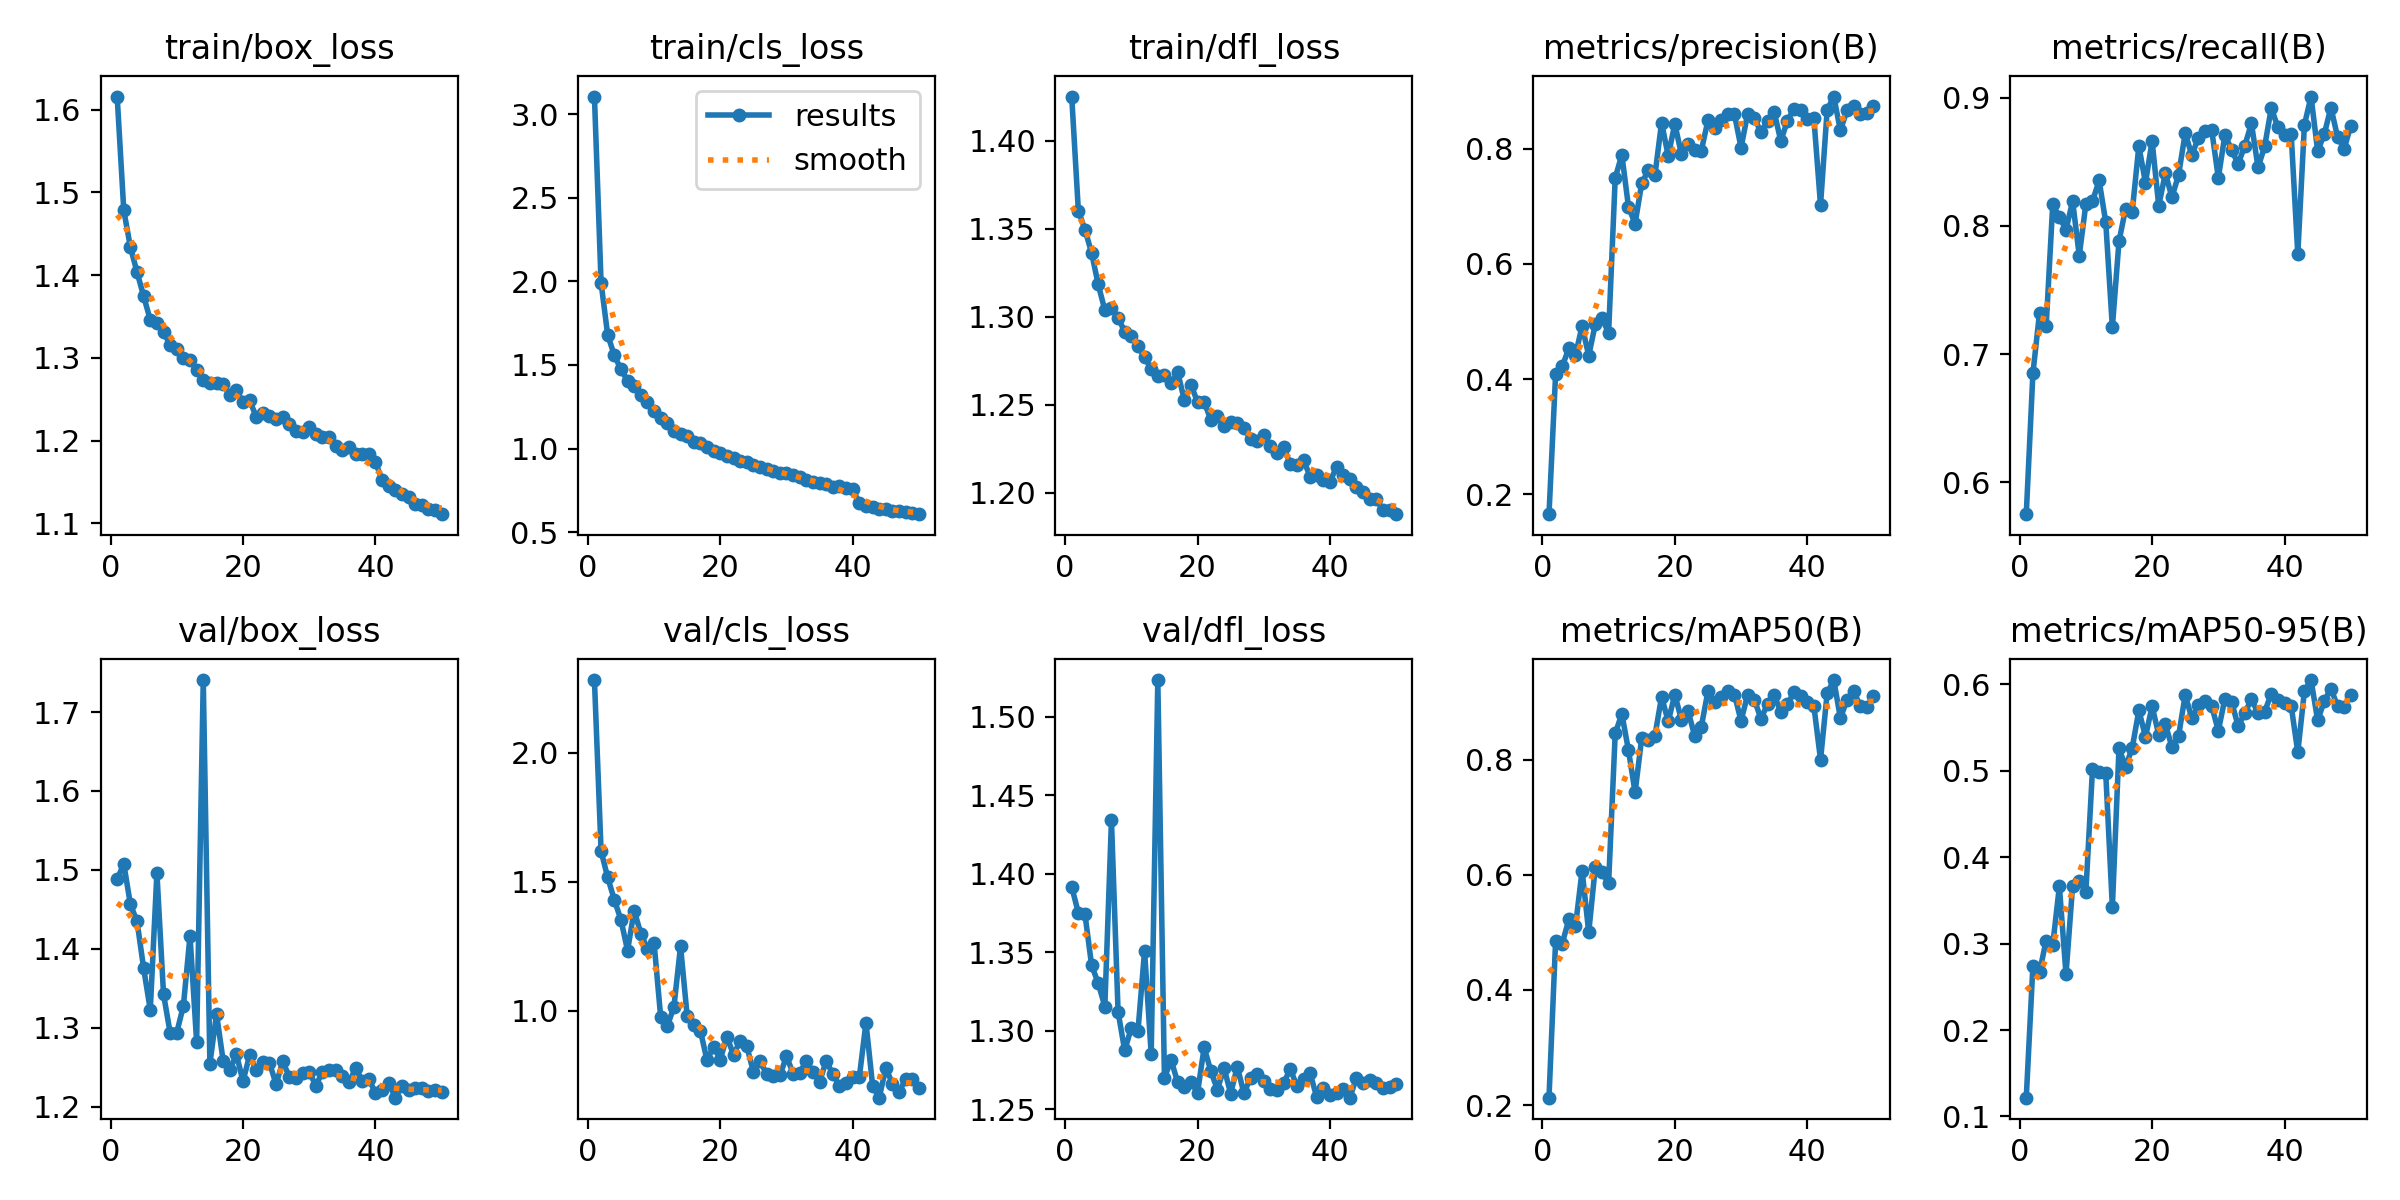


confusion_matrix.png:


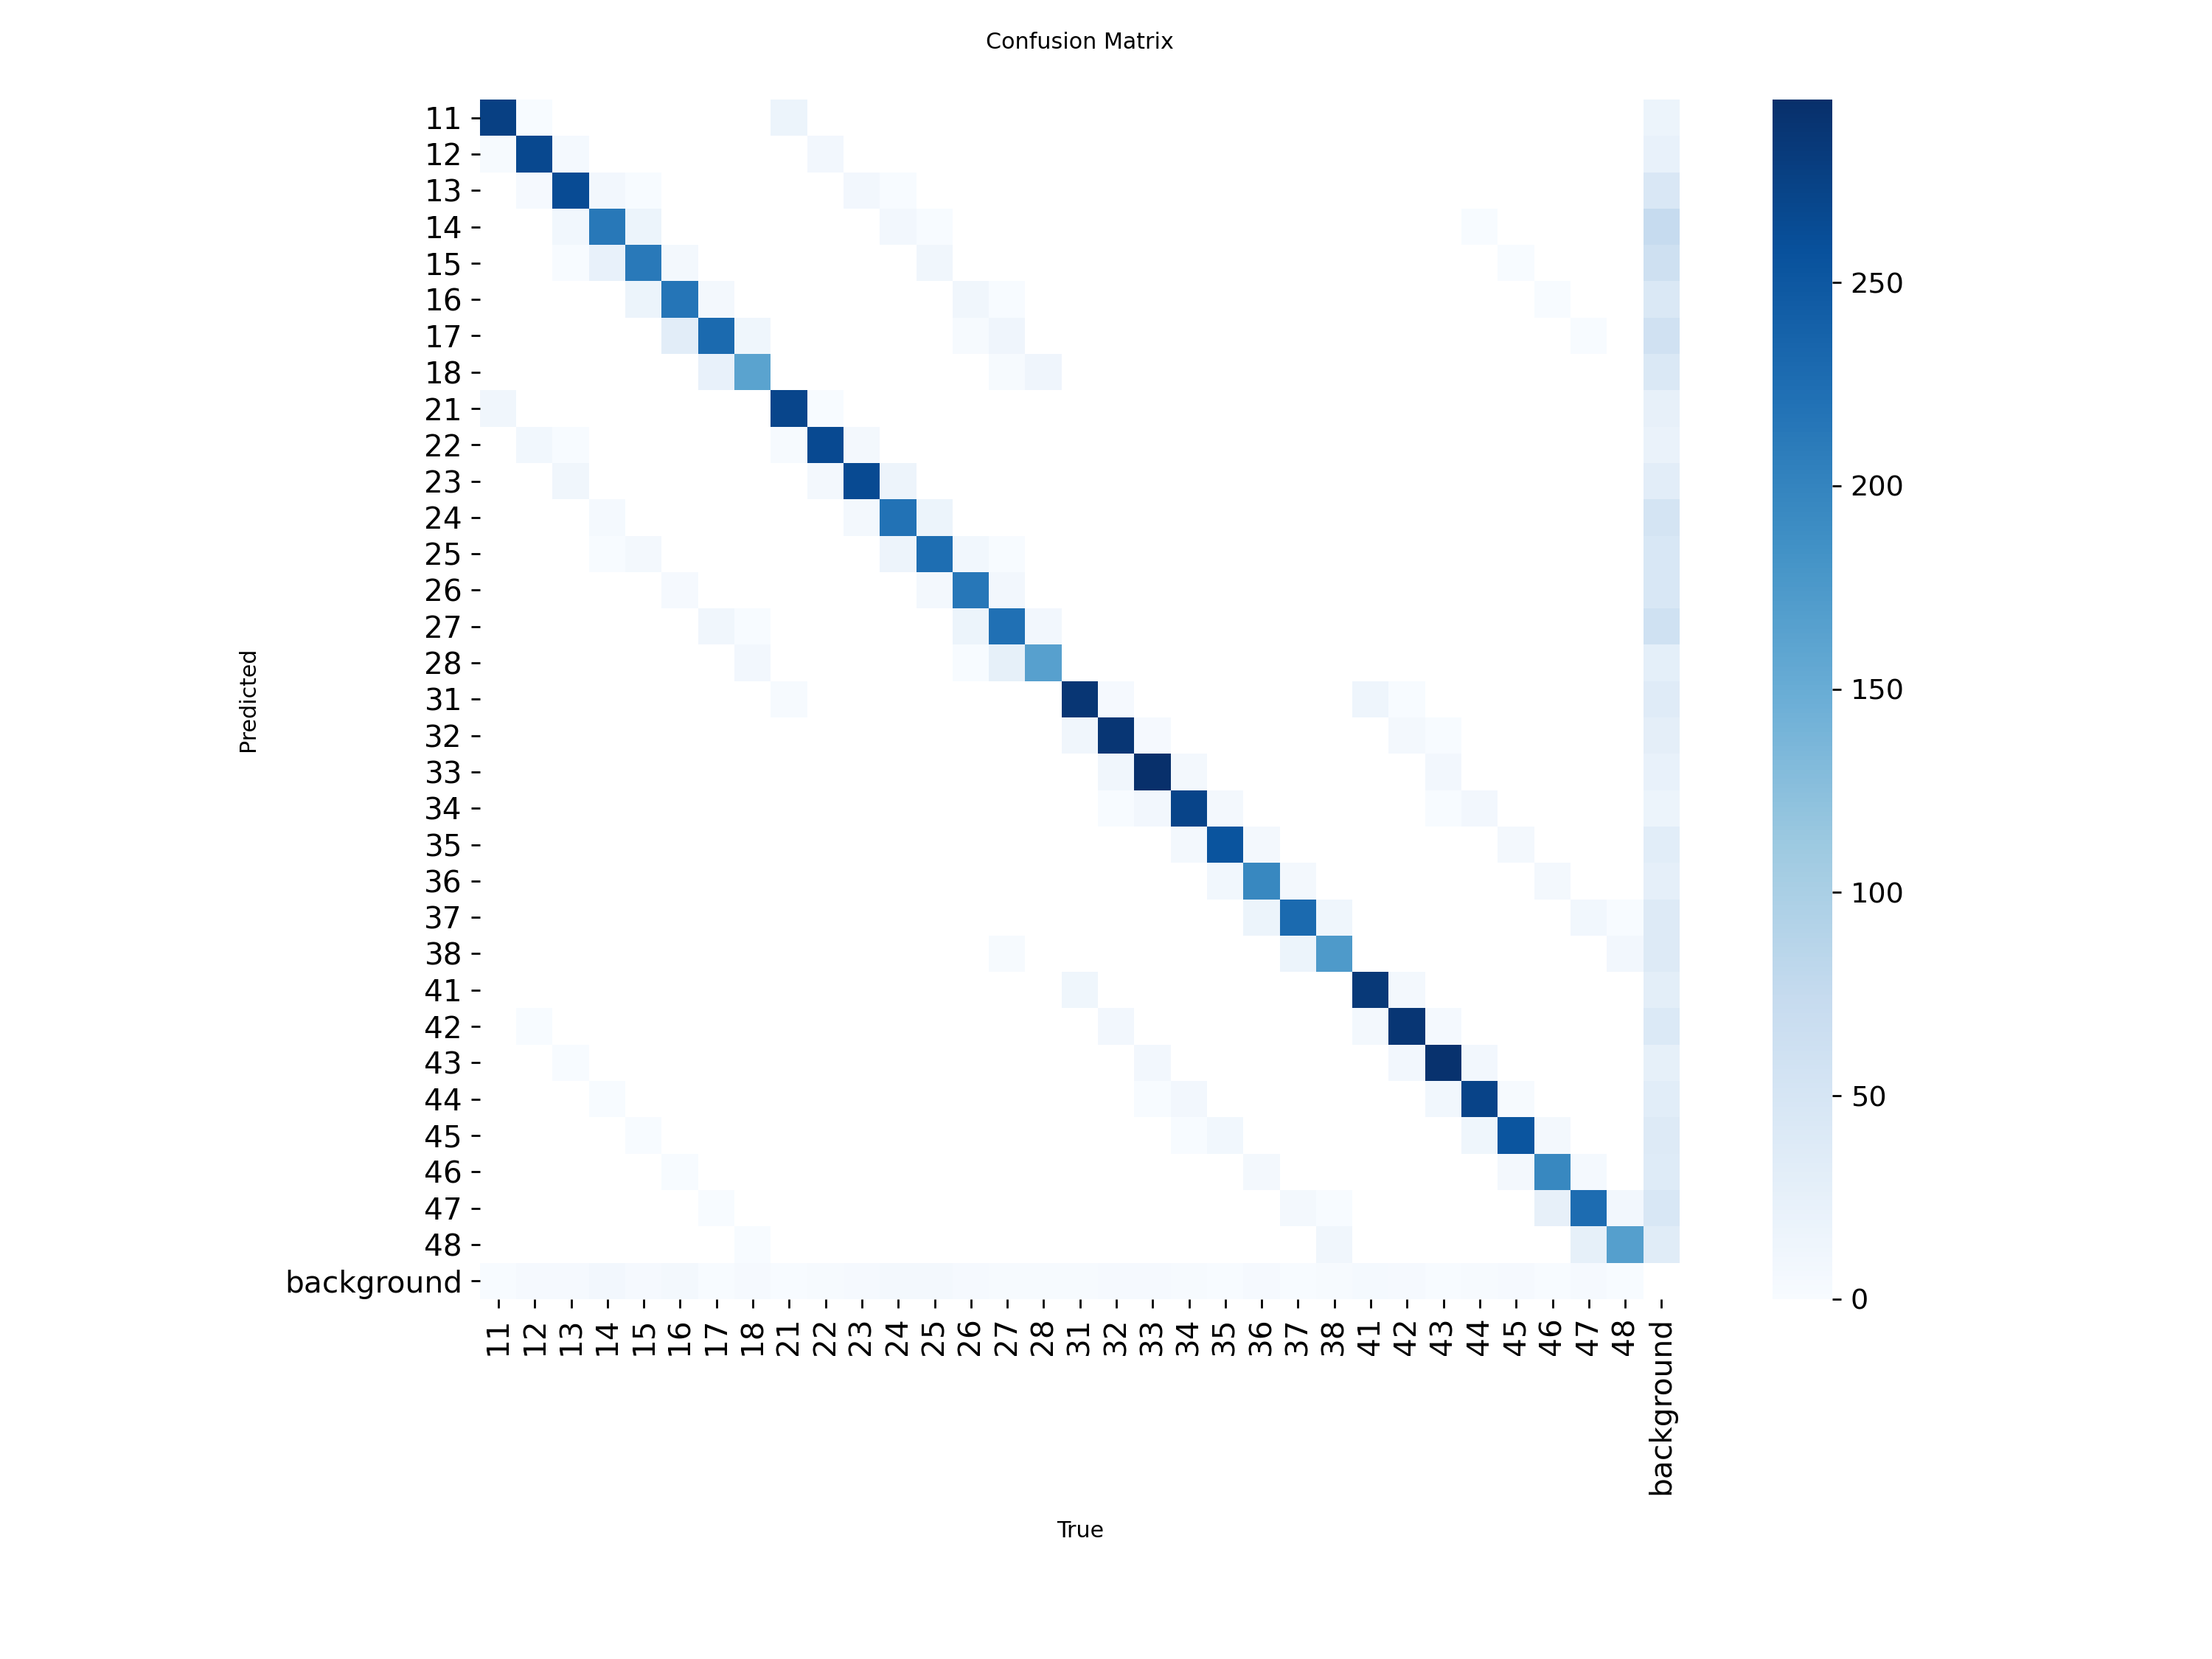

In [ ]:
from IPython.display import Image, display
import os

results_dir = '/content/drive/MyDrive/dental_runs/opg_v1'

# Show training plots saved automatically by YOLO
for plot in ['results.png', 'confusion_matrix.png', 'PR_curve.png']:
    path = os.path.join(results_dir, plot)
    if os.path.exists(path):
        print(f"\n{plot}:")
        display(Image(path, width=800))

In [ ]:
import yaml, glob
from IPython.display import Image, display
import os

# Reload dataset config
yaml_files = glob.glob('/content/dental_dataset/**/data.yaml', recursive=True)
if not yaml_files:
    # dataset was cleared on reconnect, re-extract first (see previous message)
    print("Dataset not found in /content — re-extract your zip first")
else:
    with open(yaml_files[0]) as f:
        cfg = yaml.safe_load(f)

    DATASET_ROOT = os.path.dirname(yaml_files[0])
    FDI_NAMES = cfg['names']

    # Get test images (fall back to valid if no test split)
    test_imgs = glob.glob(f"{DATASET_ROOT}/test/images/*")
    if not test_imgs:
        test_imgs = glob.glob(f"{DATASET_ROOT}/valid/images/*")

    print(f"Found {len(test_imgs)} test images")

    # Run prediction on first 5 images
    results = model.predict(
        source=test_imgs[:5],
        conf=0.4,
        iou=0.4,
        save=True,
        project='/content/drive/MyDrive/dental_runs',
        name='predictions',
    )

    # Print detected teeth per image
    for i, res in enumerate(results):
        detected = []
        for box in res.boxes:
            fdi = FDI_NAMES[int(box.cls)]
            conf = round(float(box.conf), 3)
            detected.append((fdi, conf))
        detected.sort(key=lambda x: int(x[0]))

        print(f"\nImage {i+1}: {os.path.basename(res.path)}")
        print(f"  Detected {len(detected)} teeth: {[d[0] for d in detected]}")
        for fdi, conf in detected:
            print(f"    Tooth {fdi}  conf={conf}")

Found 156 test images

0: 640x640 1 11, 1 12, 2 13s, 1 14, 3 15s, 1 16, 1 17, 1 21, 1 22, 1 23, 1 24, 2 25s, 2 26s, 1 27, 1 31, 1 32, 1 33, 2 34s, 2 35s, 1 36, 1 37, 1 38, 1 41, 1 42, 1 43, 1 44, 2 45s, 1 46, 1 47, 17.7ms
1: 640x640 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 17.7ms
2: 640x640 1 11, 2 12s, 1 13, 2 14s, 3 15s, 1 16, 1 17, 1 21, 1 22, 2 23s, 2 24s, 3 25s, 1 26, 1 27, 1 28, 1 31, 1 32, 2 33s, 1 34, 1 35, 1 36, 1 37, 2 38s, 1 41, 2 42s, 2 43s, 2 44s, 2 45s, 1 46, 1 47, 1 48, 17.7ms
3: 640x640 1 18, 1 25, 1 28, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 41, 1 42, 1 43, 1 44, 1 45, 1 47, 1 48, 17.7ms
4: 640x640 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 17.7ms
Speed: 4.1ms preprocess, 17.7ms inferenc

image0.jpg


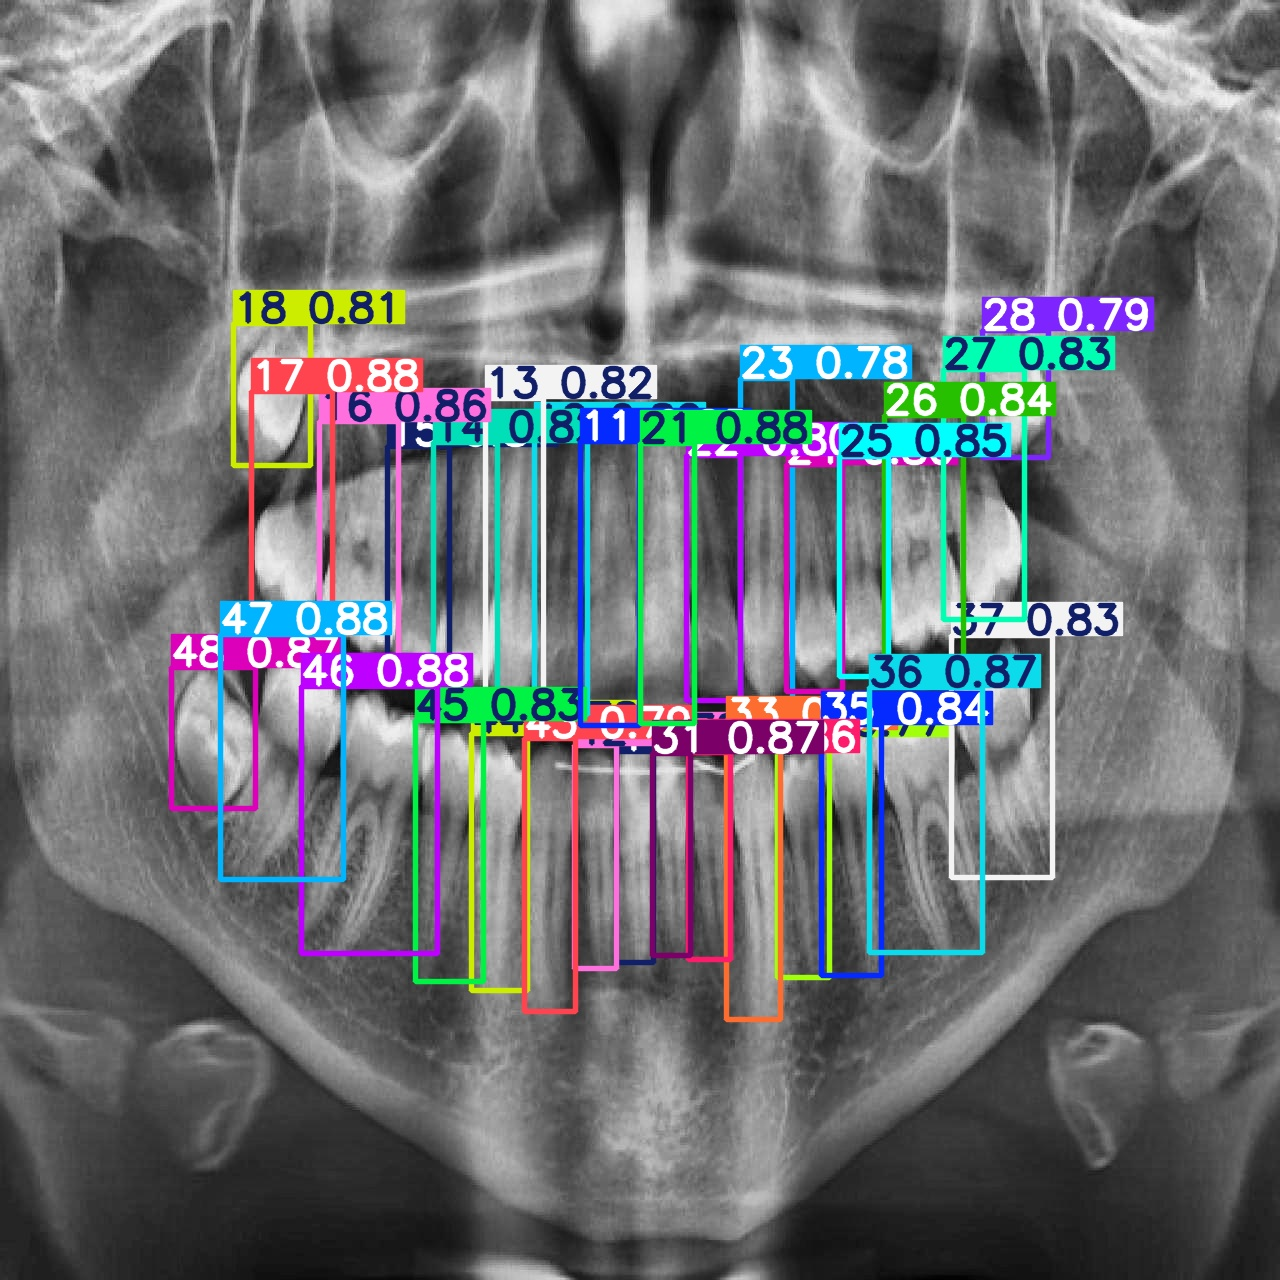

image1.jpg


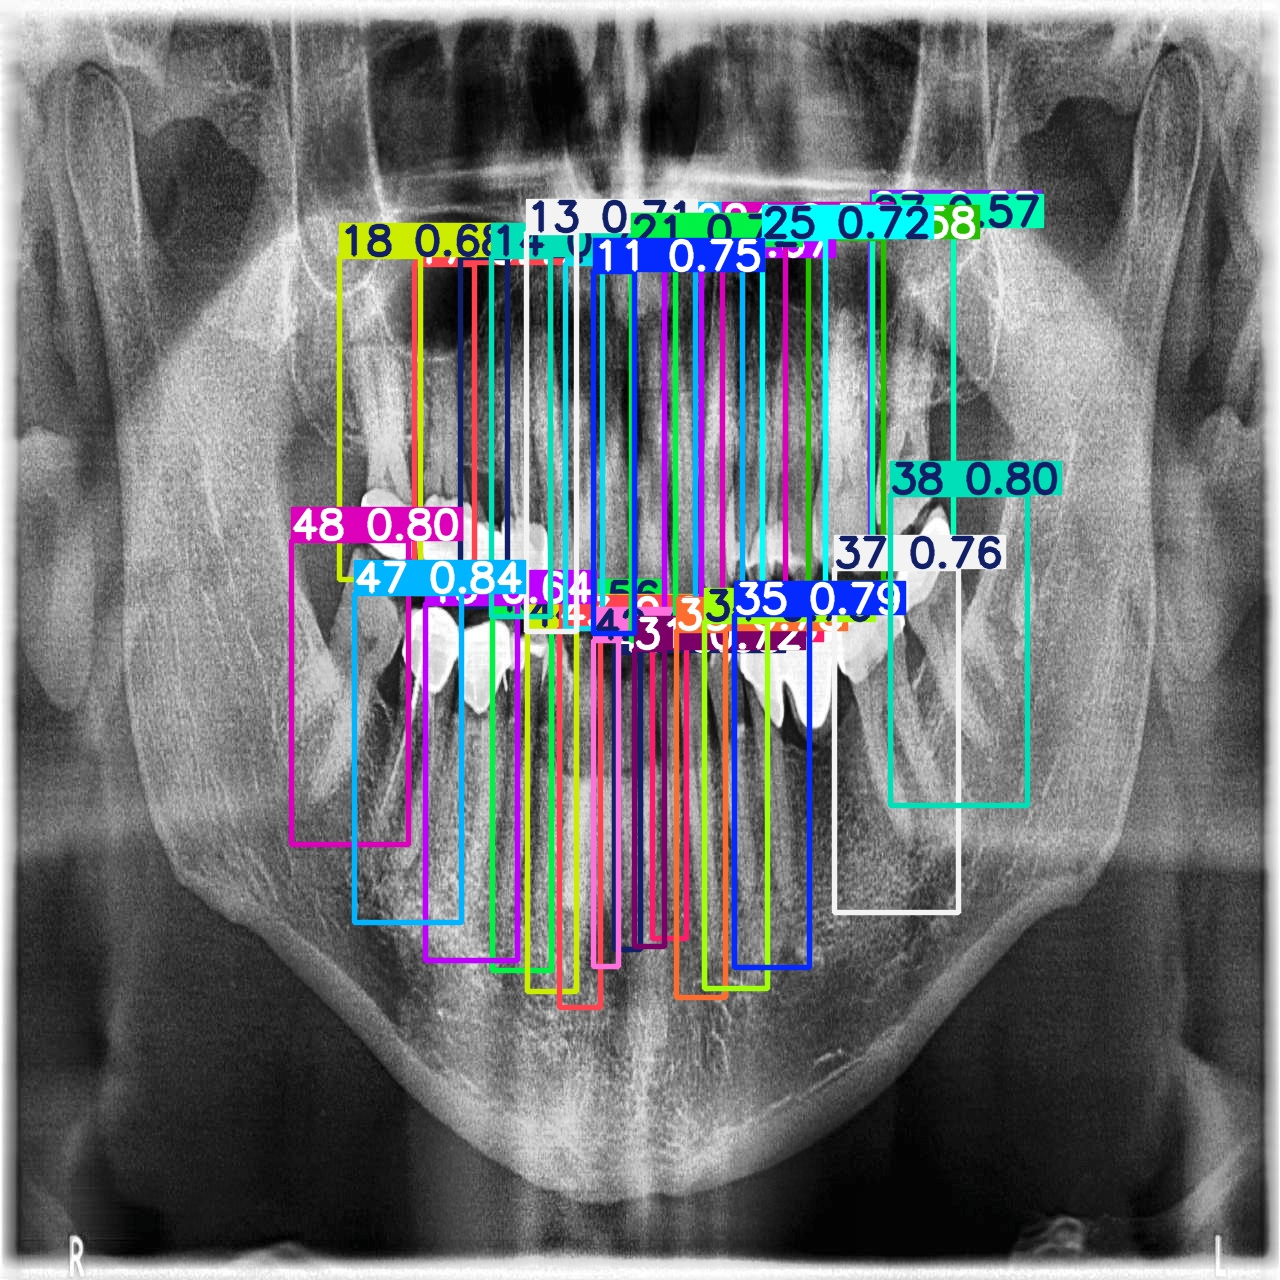

image2.jpg


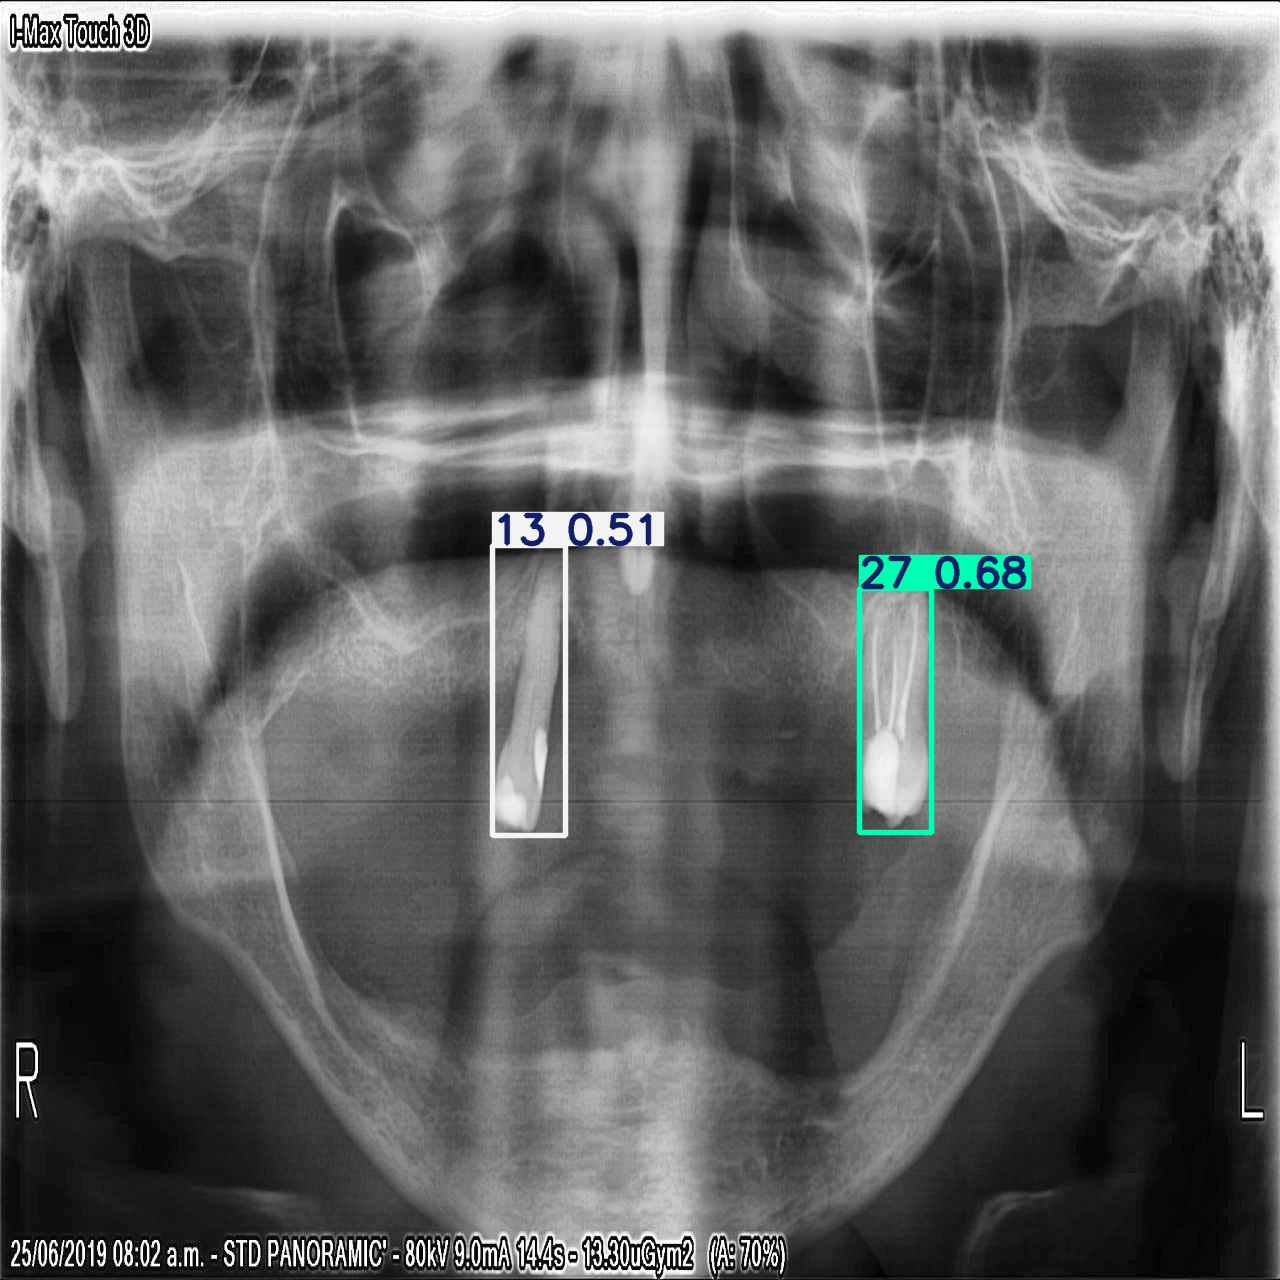

image3.jpg


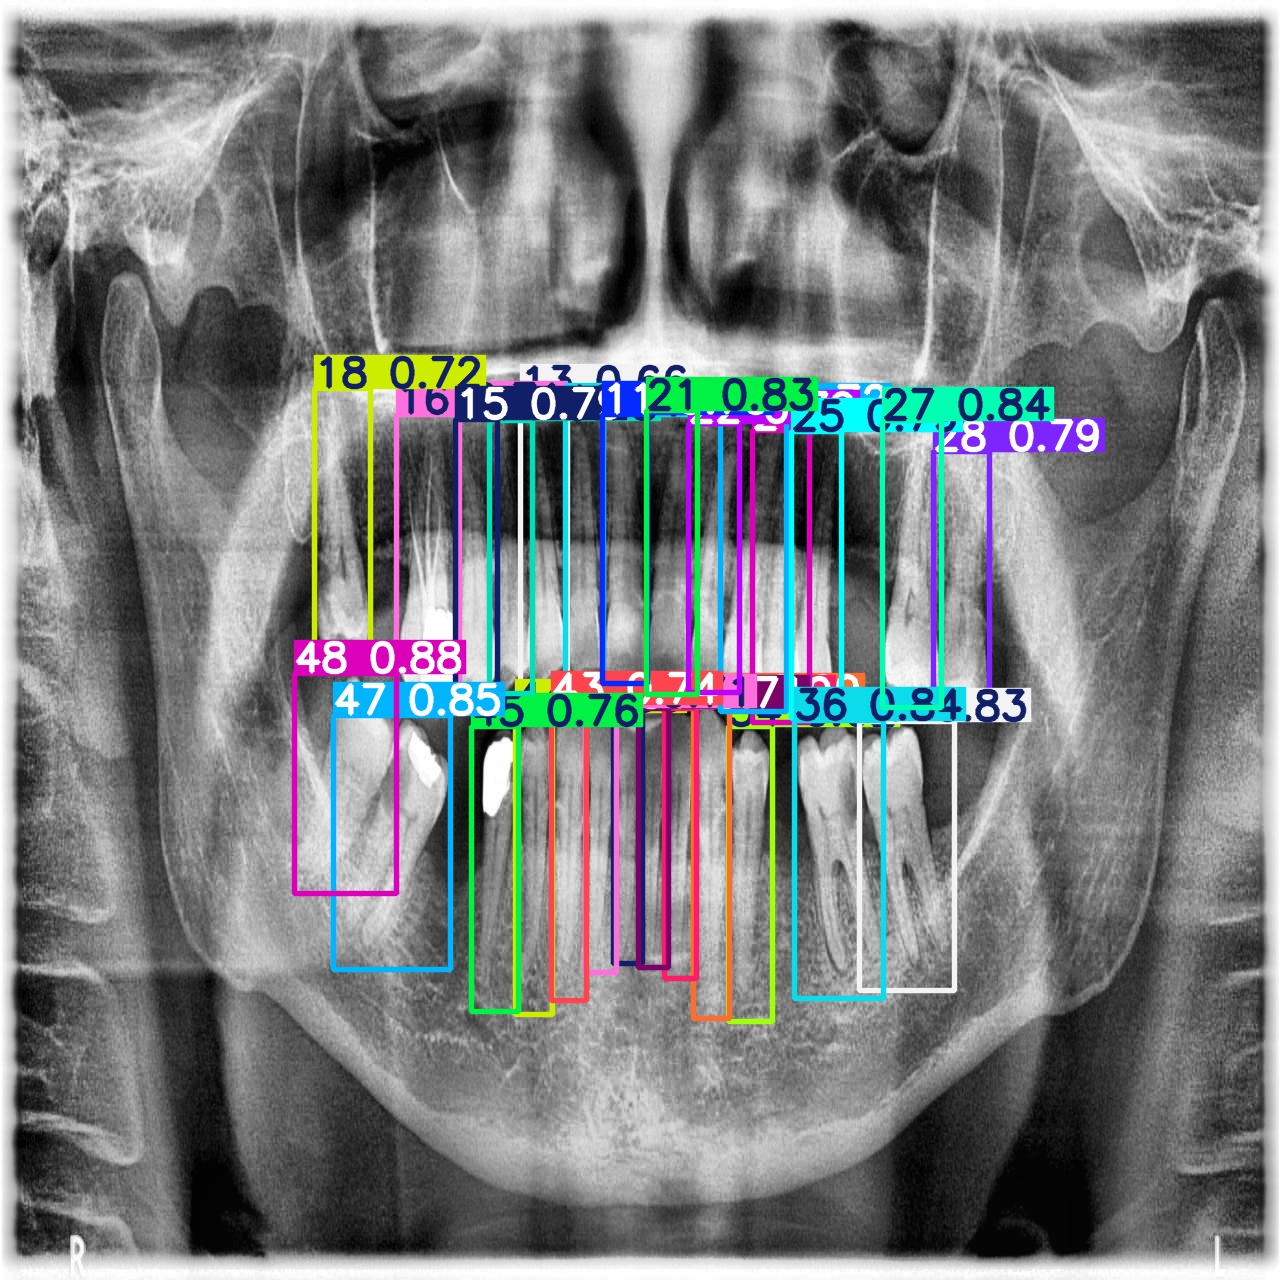

image4.jpg


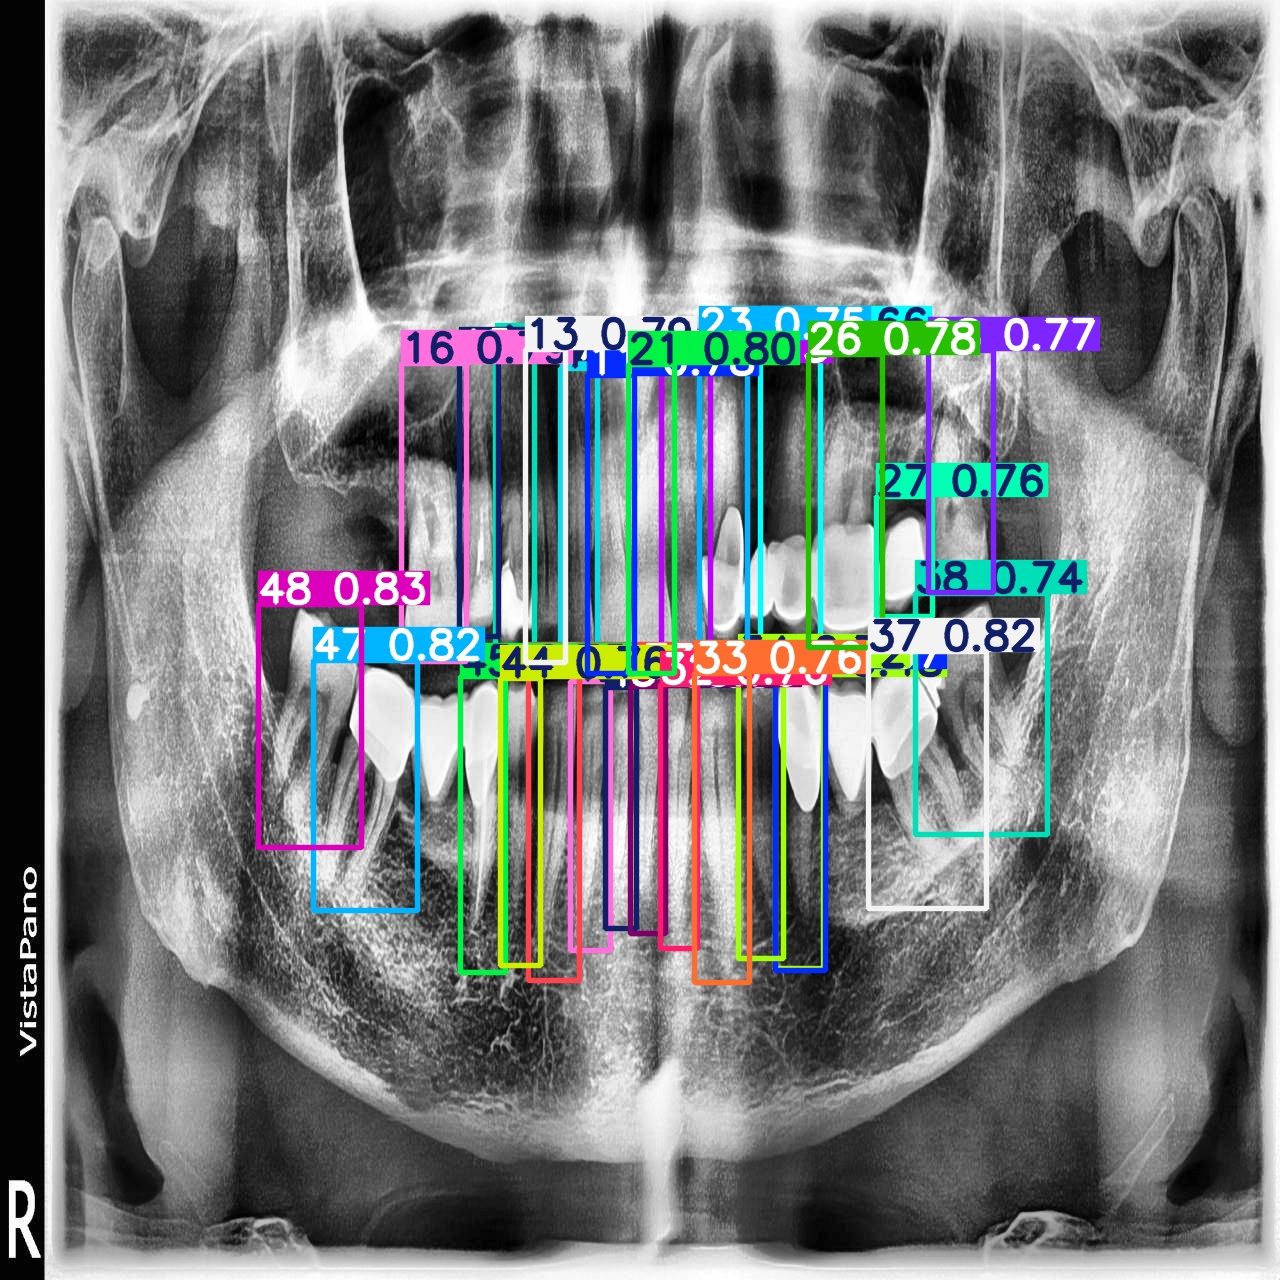

In [ ]:
# Show the saved prediction images
pred_imgs = glob.glob('/content/drive/MyDrive/dental_runs/predictions/*.jpg')
pred_imgs += glob.glob('/content/drive/MyDrive/dental_runs/predictions/*.png')

for img_path in pred_imgs[:5]:
    print(os.path.basename(img_path))
    display(Image(img_path, width=900))

Saving train_588_png_jpg.rf.410b78e9119992fbd5a7db57de0f67f6.jpg to train_588_png_jpg.rf.410b78e9119992fbd5a7db57de0f67f6.jpg

image 1/1 /content/train_588_png_jpg.rf.410b78e9119992fbd5a7db57de0f67f6.jpg: 640x640 1 11, 1 12, 1 13, 1 14, 1 15, 1 16, 1 17, 1 18, 1 21, 1 22, 1 23, 1 24, 1 25, 1 26, 1 27, 1 28, 1 31, 1 32, 1 33, 1 34, 1 35, 1 36, 1 37, 1 38, 1 41, 1 42, 1 43, 1 44, 1 45, 1 46, 1 47, 1 48, 8.4ms
Speed: 3.8ms preprocess, 8.4ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/dental_runs/my_prediction3
Detected 32 teeth:

  Tooth 11  conf=0.646  bbox=[538,593,877,642]
  Tooth 12  conf=0.598  bbox=[537,556,892,600]
  Tooth 13  conf=0.56  bbox=[526,516,883,570]
  Tooth 14  conf=0.583  bbox=[511,489,864,539]
  Tooth 15  conf=0.623  bbox=[503,450,836,509]
  Tooth 16  conf=0.813  bbox=[489,400,797,474]
  Tooth 17  conf=0.842  bbox=[499,348,803,421]
  Tooth 18  conf=0.715  bbox=[617,312,875,392]
  Tooth 21  conf=0.765  bbox=[5

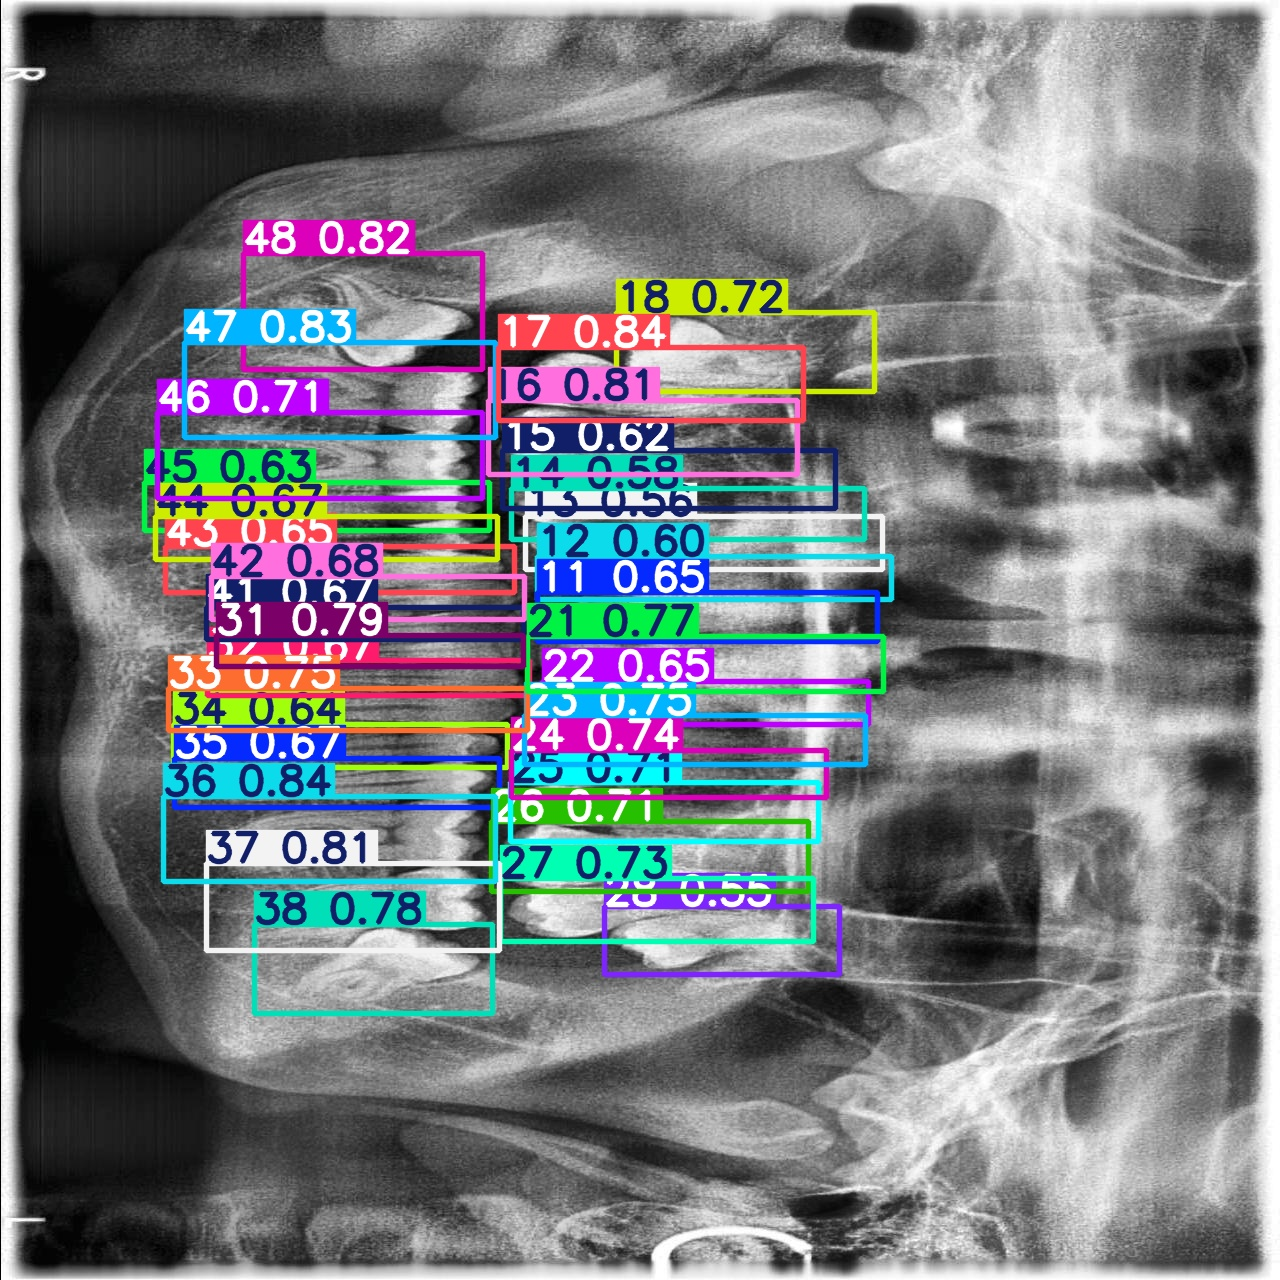

In [ ]:
from google.colab import files

# Upload any new OPG image from your PC
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# Run prediction
res = model.predict(
    img_path,
    conf=0.4,
    iou=0.4,
    save=True,
    project='/content/drive/MyDrive/dental_runs',
    name='my_prediction'
)[0]

# Print results
print(f"Detected {len(res.boxes)} teeth:\n")
detected = []
for box in res.boxes:
    fdi = FDI_NAMES[int(box.cls)]
    conf = round(float(box.conf), 3)
    x1, y1, x2, y2 = [round(v) for v in box.xyxy[0].tolist()]
    detected.append((fdi, conf, x1, y1, x2, y2))

detected.sort(key=lambda x: int(x[0]))
for fdi, conf, x1, y1, x2, y2 in detected:
    print(f"  Tooth {fdi}  conf={conf}  bbox=[{x1},{y1},{x2},{y2}]")

# Display result image
from pathlib import Path

# Display result image
saved_imgs = list(Path(res.save_dir).glob('*'))
if saved_imgs:
    display(Image(str(saved_imgs[0]), width=900))
else:
    print("No saved image found")

Saving 77_jpg.rf.c307936a62e7f23a6067adbb6c0aedb5.jpg to 77_jpg.rf.c307936a62e7f23a6067adbb6c0aedb5.jpg

image 1/1 /content/77_jpg.rf.c307936a62e7f23a6067adbb6c0aedb5.jpg: 640x640 1 13, 1 31, 1 32, 1 33, 1 34, 1 35, 1 41, 1 42, 1 43, 8.1ms
Speed: 2.6ms preprocess, 8.1ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/dental_runs/my_prediction4
Detected 9 teeth:

  Tooth 13  conf=0.583  bbox=[544,483,836,532]
  Tooth 31  conf=0.839  bbox=[388,635,600,668]
  Tooth 32  conf=0.778  bbox=[386,666,623,703]
  Tooth 33  conf=0.798  bbox=[344,702,633,762]
  Tooth 34  conf=0.708  bbox=[378,753,637,804]
  Tooth 35  conf=0.572  bbox=[377,752,637,803]
  Tooth 41  conf=0.745  bbox=[379,600,601,634]
  Tooth 42  conf=0.718  bbox=[364,563,601,600]
  Tooth 43  conf=0.798  bbox=[309,512,596,565]


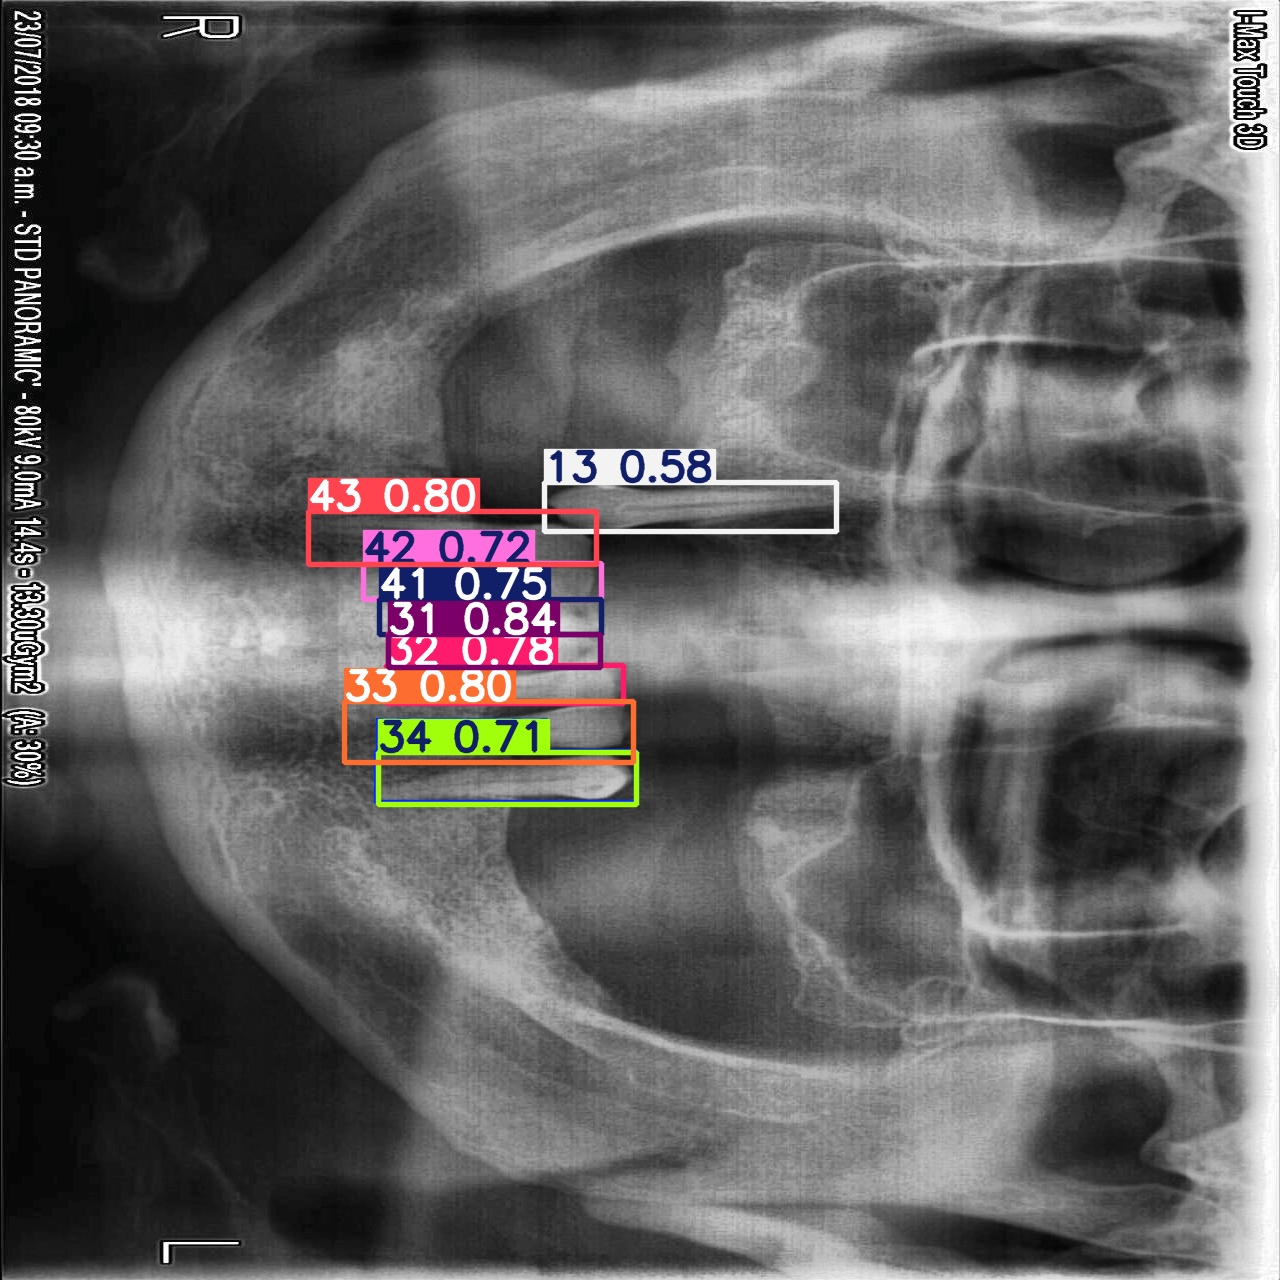

In [ ]:
from google.colab import files

# Upload any new OPG image from your PC
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# Run prediction
res = model.predict(
    img_path,
    conf=0.4,
    iou=0.4,
    save=True,
    project='/content/drive/MyDrive/dental_runs',
    name='my_prediction'
)[0]

# Print results
print(f"Detected {len(res.boxes)} teeth:\n")
detected = []
for box in res.boxes:
    fdi = FDI_NAMES[int(box.cls)]
    conf = round(float(box.conf), 3)
    x1, y1, x2, y2 = [round(v) for v in box.xyxy[0].tolist()]
    detected.append((fdi, conf, x1, y1, x2, y2))

detected.sort(key=lambda x: int(x[0]))
for fdi, conf, x1, y1, x2, y2 in detected:
    print(f"  Tooth {fdi}  conf={conf}  bbox=[{x1},{y1},{x2},{y2}]")

# Display result image
from pathlib import Path

# Display result image
saved_imgs = list(Path(res.save_dir).glob('*'))
if saved_imgs:
    display(Image(str(saved_imgs[0]), width=900))
else:
    print("No saved image found")
